# Galaxy Image Classification

Example of CNN classifier based in the dataset provided for the 'Galaxy Zoo' Kaggle competition

`https://www.kaggle.com/competitions/galaxy-zoo-the-galaxy-challenge/overview`

Some code snippets are taken from the submitted solutions.

Data is also (temporarly) available from

`wget http://personalpages.to.infn.it/~badger/galaxy-data/galaxy-zoo-the-galaxy-challenge.zip`

In [4]:
import numpy as np
import pandas as pd
import os

from sklearn.model_selection import train_test_split

from skimage import io
from skimage import color
from skimage.transform import resize

from tqdm import tqdm

import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

In [5]:
df = pd.read_csv('galaxy-zoo/training_solutions_rev1.csv')

df_train_and_validation, df_test = train_test_split(df, test_size=0.7)

df_train, df_val = train_test_split(df_train_and_validation, test_size=0.2)
df_train.shape, df_val.shape, df_test.shape

((14778, 38), (3695, 38), (43105, 38))

In [6]:
df_train

,GalaxyID,Class1.1,Class1.2,Class1.3,Class2.1,Class2.2,Class3.1,Class3.2,Class4.1,Class4.2,...,Class9.3,Class10.1,Class10.2,Class10.3,Class11.1,Class11.2,Class11.3,Class11.4,Class11.5,Class11.6
10135,250318,0.146457,0.853543,0.000000,0.688118,0.165425,0.000000,0.165425,0.000000,0.165425,...,0.586391,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
33045,584650,0.148012,0.851988,0.000000,0.153739,0.698249,0.164792,0.533458,0.414396,0.283854,...,0.000000,0.081870,0.183683,0.148843,0.151169,0.180602,0.000000,0.000000,0.000000,0.082624
29732,535902,0.185749,0.814251,0.000000,0.073489,0.740762,0.066407,0.674355,0.516489,0.224273,...,0.029229,0.416851,0.099638,0.000000,0.000000,0.062653,0.000000,0.000000,0.000000,0.453836
7007,203464,0.969929,0.030071,0.000000,0.000000,0.030071,0.000000,0.030071,0.000000,0.030071,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
11951,277053,0.299203,0.679976,0.020821,0.281290,0.398686,0.139468,0.259219,0.193823,0.204863,...,0.000000,0.000000,0.129280,0.064543,0.000000,0.064543,0.000000,0.000000,0.000000,0.129280
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40077,684251,0.190575,0.809425,0.000000,0.051722,0.757703,0.710796,0.046906,0.144165,0.613538,...,0.000000,0.000000,0.072083,0.072083,0.000000,0.108124,0.000000,0.000000,0.000000,0.036041
16087,337884,0.681752,0.318248,0.000000,0.000000,0.318248,0.171588,0.146660,0.178211,0.140037,...,0.000000,0.000000,0.178211,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.178211
56447,924489,0.850846,0.104279,0.044875,0.000000,0.104279,0.000000,0.104279,0.000000,0.104279,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
15215,325304,0.026000,0.942000,0.032000,0.025434,0.916566,0.763499,0.153067,0.686508,0.230058,...,0.000000,0.510762,0.150345,0.025401,0.050802,0.153091,0.076889,0.025401,0.025401,0.354925


[969744 942491 421513 405036 481202 393009 659601 351015 534266 162233
 521706 993982 555472 440669 468648 585472]


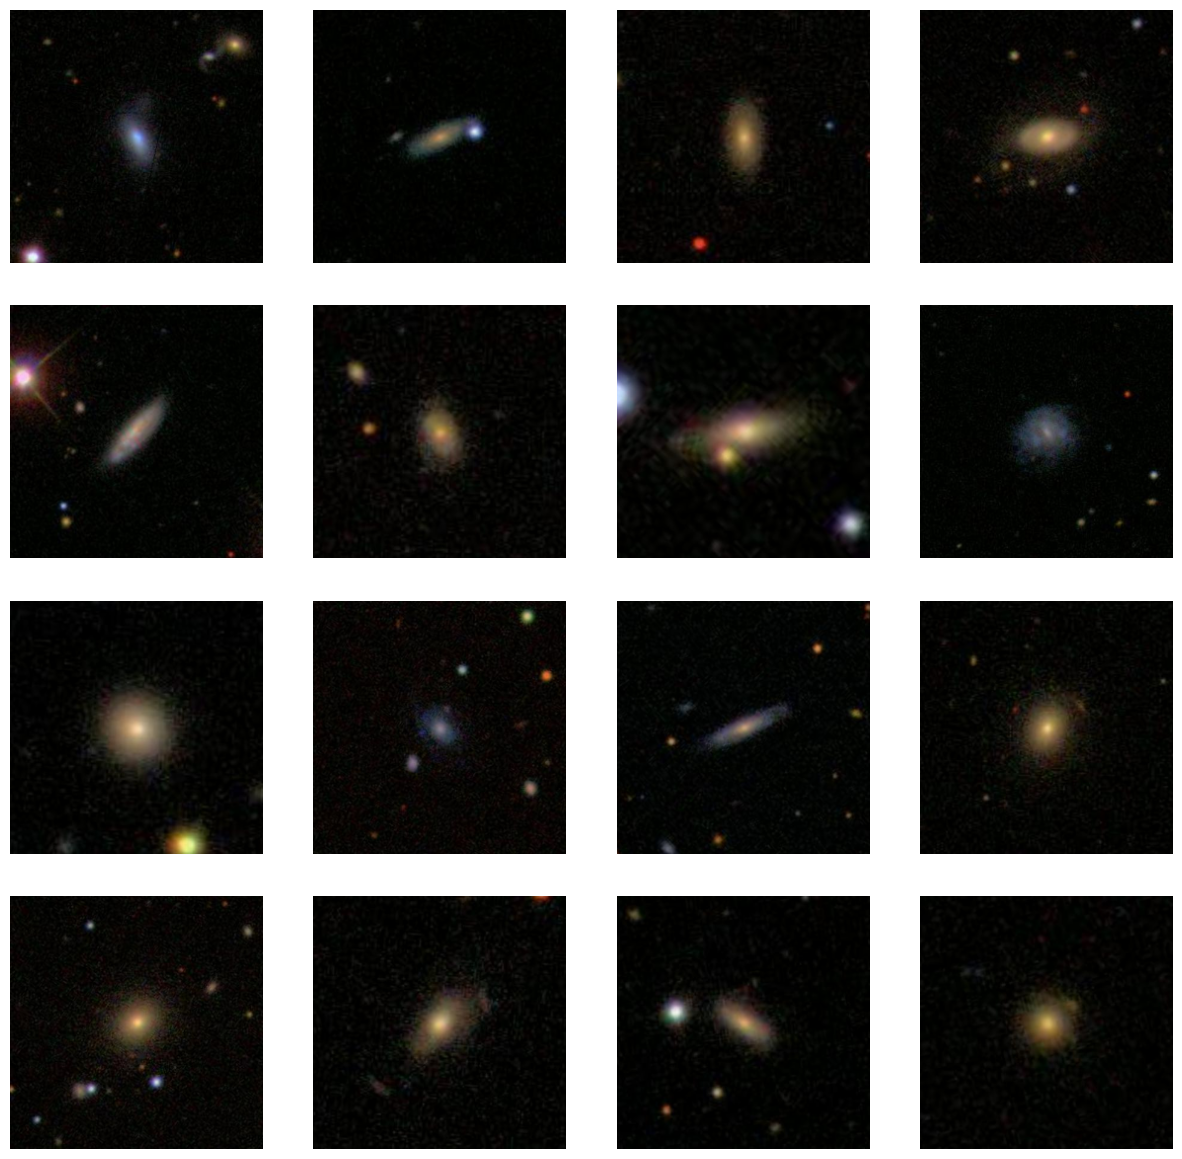

In [7]:
image_ids = np.random.choice(np.array(df_train['GalaxyID']), size=16)
print(image_ids)
image_paths = ['galaxy-zoo/images_training_rev1/'+str(im)+'.jpg' for im in image_ids]

# Load and display the images in a grid
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(15, 15))

plt.subplots_adjust(hspace=0.1)

for ax, image_path in zip(axes.flat, image_paths):
    # Load the image using skimage.io.imread
    image = io.imread(image_path)
    
    # Resize the image for consistent display
    image = resize(image, (256, 256))
    
    # If the image has an alpha channel, remove it
    if image.shape[-1] == 4:
        image = color.rgba2rgb(image)
    
    ax.imshow(image)
    ax.axis('off')


In [8]:
classnames = df.columns.tolist()
print(classnames[1:4])
print(classnames[4:6])
print(classnames[6:8])
print(classnames[8:10])
print(classnames[10:14])
print(classnames[14:16])
print(classnames[16:19])
print(classnames[19:26])
print(classnames[26:29])
print(classnames[29:32])
print(classnames[32:37])

class_start = [1,4,6,8,10,14,16,19,26,29,32]
class_end = [4,6,8,10,14,16,19,26,29,32,37]

for cl in range(len(class_start)):
    print('class',cl, 'sum =', np.sum(df.values[23,class_start[cl]:class_end[cl]]))

np.sum(df.values[23,1:])

['Class1.1', 'Class1.2', 'Class1.3']
['Class2.1', 'Class2.2']
['Class3.1', 'Class3.2']
['Class4.1', 'Class4.2']
['Class5.1', 'Class5.2', 'Class5.3', 'Class5.4']
['Class6.1', 'Class6.2']
['Class7.1', 'Class7.2', 'Class7.3']
['Class8.1', 'Class8.2', 'Class8.3', 'Class8.4', 'Class8.5', 'Class8.6', 'Class8.7']
['Class9.1', 'Class9.2', 'Class9.3']
['Class10.1', 'Class10.2', 'Class10.3']
['Class11.1', 'Class11.2', 'Class11.3', 'Class11.4', 'Class11.5']
class 0 sum = 1.0
class 1 sum = 0.74281
class 2 sum = 0.7428100000000001
class 3 sum = 0.74281
class 4 sum = 0.742809257
class 5 sum = 1.0
class 6 sum = 0.256861
class 7 sum = 0.23701
class 8 sum = 0.0
class 9 sum = 0.41290356699999997
class 10 sum = 0.214271351


6.290917390000001

In [14]:
ORIG_SHAPE = (424,424)
CROP_SIZE = (256,256)
IMG_SIZE = 64
IMG_SHAPE = (IMG_SIZE,IMG_SIZE)

def get_image(path, x1,y1, shape, crop_size):
    x = plt.imread(path)
    x = x[x1:x1+crop_size[0], y1:y1+crop_size[1]]
    x = resize(x, shape)
    x = x/255.
    return x

def get_all_images(dataframe, shape=IMG_SHAPE, crop_size=CROP_SIZE, max_images=-1):
    x1 = (ORIG_SHAPE[0]-CROP_SIZE[0])//2
    y1 = (ORIG_SHAPE[1]-CROP_SIZE[1])//2
  
    max = len(dataframe)
    if max_images>0:
        max = max_images
   
    sel = dataframe.values
    ids = sel[:max,0].astype(int).astype(str)
    
    y_batch = sel[:max,1:]
    x_batch = []
    for i in tqdm(ids):
        x = get_image('galaxy-zoo/images_training_rev1/'+i+'.jpg', x1,y1, shape=shape, crop_size=crop_size)
        x_batch.append(x)
    x_batch = np.array(x_batch)
    return x_batch, y_batch

In [10]:
X_train, y_train = get_all_images(df_train)
X_val, y_val = get_all_images(df_val)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3695/3695 [00:31<00:00, 118.92it/s]


In [22]:
tf.keras.backend.clear_session()

In [23]:
def build_pretrained_model():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # EfficientNetB0 backbone, include top=False for custom head
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs,
        pooling='avg'   # GlobalAveragePooling
    )
    
    # Optional: freeze base model layers (here we keep all trainable)
    base_model.trainable = False
    
    x = base_model.output
    x = layers.Dropout(0.3)(x)             # regularization
    outputs = layers.Dense(37, activation='sigmoid')(x)
    
    model = models.Model(inputs, outputs)
    return model

model = build_pretrained_model()
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 64, 64, 3)]  0           []                               
                                                                                                  
 rescaling (Rescaling)          (None, 64, 64, 3)    0           ['input_1[0][0]']                
                                                                                                  
 normalization (Normalization)  (None, 64, 64, 3)    7           ['rescaling[0][0]']              
                                                                                                  
 rescaling_1 (Rescaling)        (None, 64, 64, 3)    0           ['normalization[0][0]']          
                                                                                              

In [24]:
def rmse(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),  # smaller LR for pretrained
    loss='mse',
    metrics=[rmse]
)

In [25]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_rmse',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_rmse',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

callbacks = [reduce_lr, early_stop]

In [26]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
462/462 [==============================] - 40s 72ms/step - loss: 0.0394 - rmse: 0.1920 - val_loss: 0.0274 - val_rmse: 0.1651 - lr: 1.0000e-04
Epoch 2/20
462/462 [==============================] - 30s 64ms/step - loss: 0.0276 - rmse: 0.1658 - val_loss: 0.0271 - val_rmse: 0.1641 - lr: 1.0000e-04
Epoch 3/20
462/462 [==============================] - 30s 65ms/step - loss: 0.0274 - rmse: 0.1651 - val_loss: 0.0270 - val_rmse: 0.1640 - lr: 1.0000e-04
Epoch 4/20
462/462 [==============================] - 30s 65ms/step - loss: 0.0273 - rmse: 0.1650 - val_loss: 0.0270 - val_rmse: 0.1640 - lr: 1.0000e-04
Epoch 5/20
462/462 [==============================] - 30s 65ms/step - loss: 0.0273 - rmse: 0.1649 - val_loss: 0.0270 - val_rmse: 0.1640 - lr: 1.0000e-04
Epoch 6/20
462/462 [==============================] - 30s 65ms/step - loss: 0.0272 - rmse: 0.1647 - val_loss: 0.0270 - val_rmse: 0.1641 - lr: 1.0000e-04
Epoch 7/20
462/462 [==============================] - 44s 96ms/step - loss: 0.0272

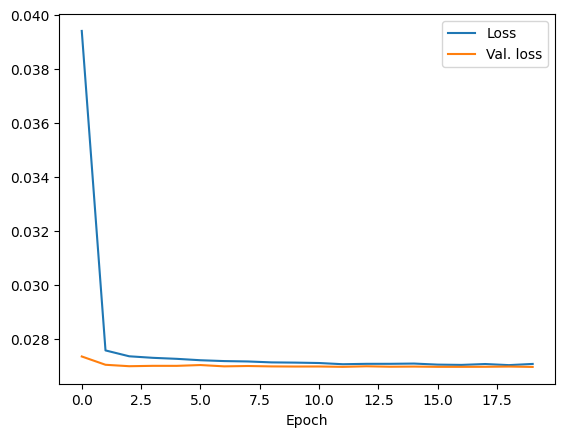

In [27]:
plt.figure()
plt.plot(history.history['loss'],label='Loss')
plt.plot(history.history['val_loss'],label='Val. loss')
plt.xlabel('Epoch')
plt.legend()

In [28]:
X_test, y_test = get_all_images(df_test)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 43105/43105 [06:13<00:00, 115.48it/s]


In [29]:
preds = model.predict(X_test)

1348/1348 [==============================] - 67s 48ms/step


In [30]:
rmse = np.sqrt(np.mean((preds - y_test) ** 2))
print(f"Overall RMSE: {rmse:.4f}")

Overall RMSE: 0.1640


In [31]:
mse_per_output = np.mean((preds - y_test)**2, axis=0)
rmse_per_output = np.sqrt(mse_per_output)

for i, rmse_val in enumerate(rmse_per_output):
    print(f"Output {i+1}: RMSE = {rmse_val:.4f}")

Output 1: RMSE = 0.2837
Output 2: RMSE = 0.2967
Output 3: RMSE = 0.0380
Output 4: RMSE = 0.2128
Output 5: RMSE = 0.3020
Output 6: RMSE = 0.1764
Output 7: RMSE = 0.2478
Output 8: RMSE = 0.2856
Output 9: RMSE = 0.1799
Output 10: RMSE = 0.0869
Output 11: RMSE = 0.1924
Output 12: RMSE = 0.1805
Output 13: RMSE = 0.0605
Output 14: RMSE = 0.2280
Output 15: RMSE = 0.2281
Output 16: RMSE = 0.2400
Output 17: RMSE = 0.2159
Output 18: RMSE = 0.1103
Output 19: RMSE = 0.1007
Output 20: RMSE = 0.0272
Output 21: RMSE = 0.0520
Output 22: RMSE = 0.0810
Output 23: RMSE = 0.0908
Output 24: RMSE = 0.1094
Output 25: RMSE = 0.0243
Output 26: RMSE = 0.1379
Output 27: RMSE = 0.0384
Output 28: RMSE = 0.0984
Output 29: RMSE = 0.1454
Output 30: RMSE = 0.1397
Output 31: RMSE = 0.1009
Output 32: RMSE = 0.0523
Output 33: RMSE = 0.1950
Output 34: RMSE = 0.0664
Output 35: RMSE = 0.0375
Output 36: RMSE = 0.0370
Output 37: RMSE = 0.1078


In [36]:
def plot_model_outputs(y_true, y_pred, n_cols=6):
    """
    Plot scatter and histogram grids for all outputs.
    
    y_true: np.array, shape (N_samples, 37)
    y_pred: np.array, same shape
    n_cols: number of columns in the grid
    """
    n_outputs = y_true.shape[1]
    n_rows = int(np.ceil(n_outputs / n_cols))

    # -------------------
    # Scatter plots
    # -------------------
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3, n_rows*3))
    axes = axes.flatten()
    
    for i in range(n_outputs):
        ax = axes[i]
        ax.scatter(y_true[:, i], y_pred[:, i], alpha=0.3, s=5)
        ax.plot([0,1], [0,1], 'r--', linewidth=1)  # identity line
        ax.set_xlim(0,1)
        ax.set_ylim(0,1)
        ax.set_title(f"Output {i+1}", fontsize=8)
        ax.tick_params(axis='both', which='major', labelsize=7)
    
    for j in range(n_outputs, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()

    # -------------------
    # Histograms with dynamic bins
    # -------------------
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*3, n_rows*3))
    axes = axes.flatten()

    for i in range(n_outputs):
        ax = axes[i]
        min_val = min(y_true[:, i].min(), y_pred[:, i].min())
        max_val = max(y_true[:, i].max(), y_pred[:, i].max())
        bins = np.linspace(min_val, max_val, 15)
        ax.hist(y_true[:, i], bins=bins, alpha=0.5, label='True')
        ax.hist(y_pred[:, i], bins=bins, alpha=0.5, label='Predicted')
        ax.set_title(f"Output {i+1}", fontsize=8)
        ax.tick_params(axis='both', which='major', labelsize=7)

    # Turn off unused axes
    for j in range(n_outputs, len(axes)):
        axes[j].axis('off')
    
    # Single legend for the figure
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', fontsize=8)
    plt.tight_layout(rect=[0,0,0.95,0.95])

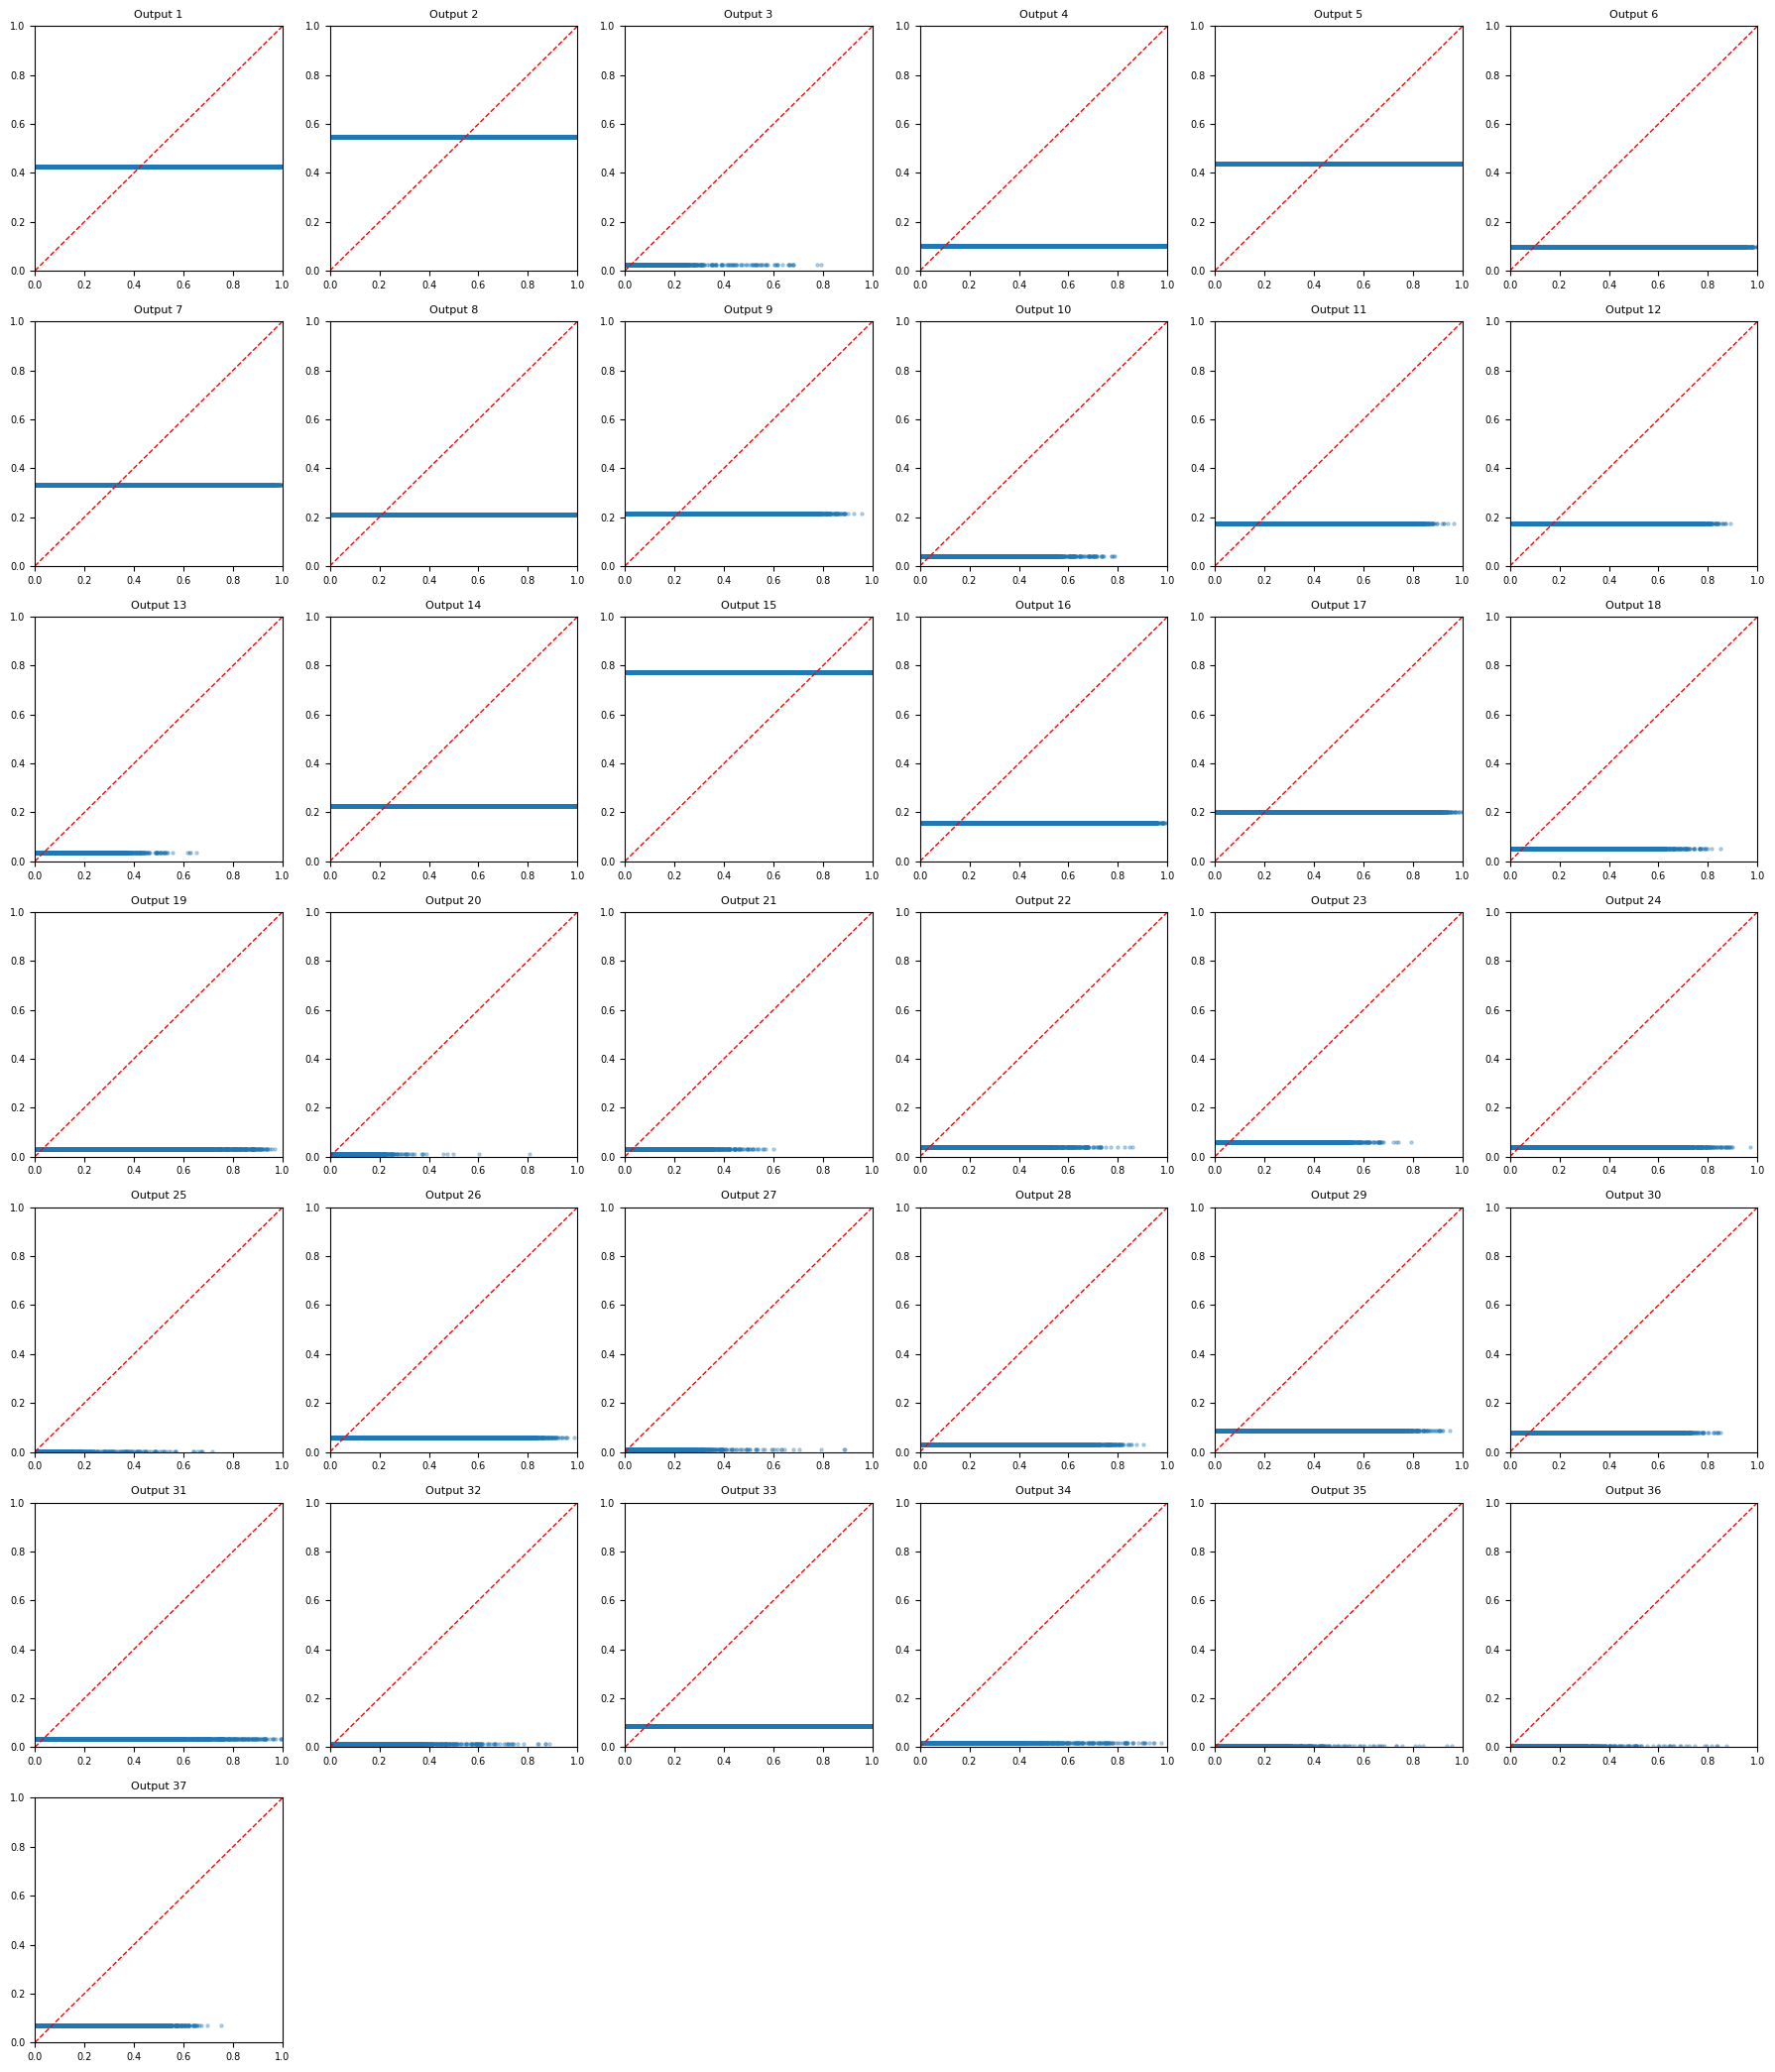

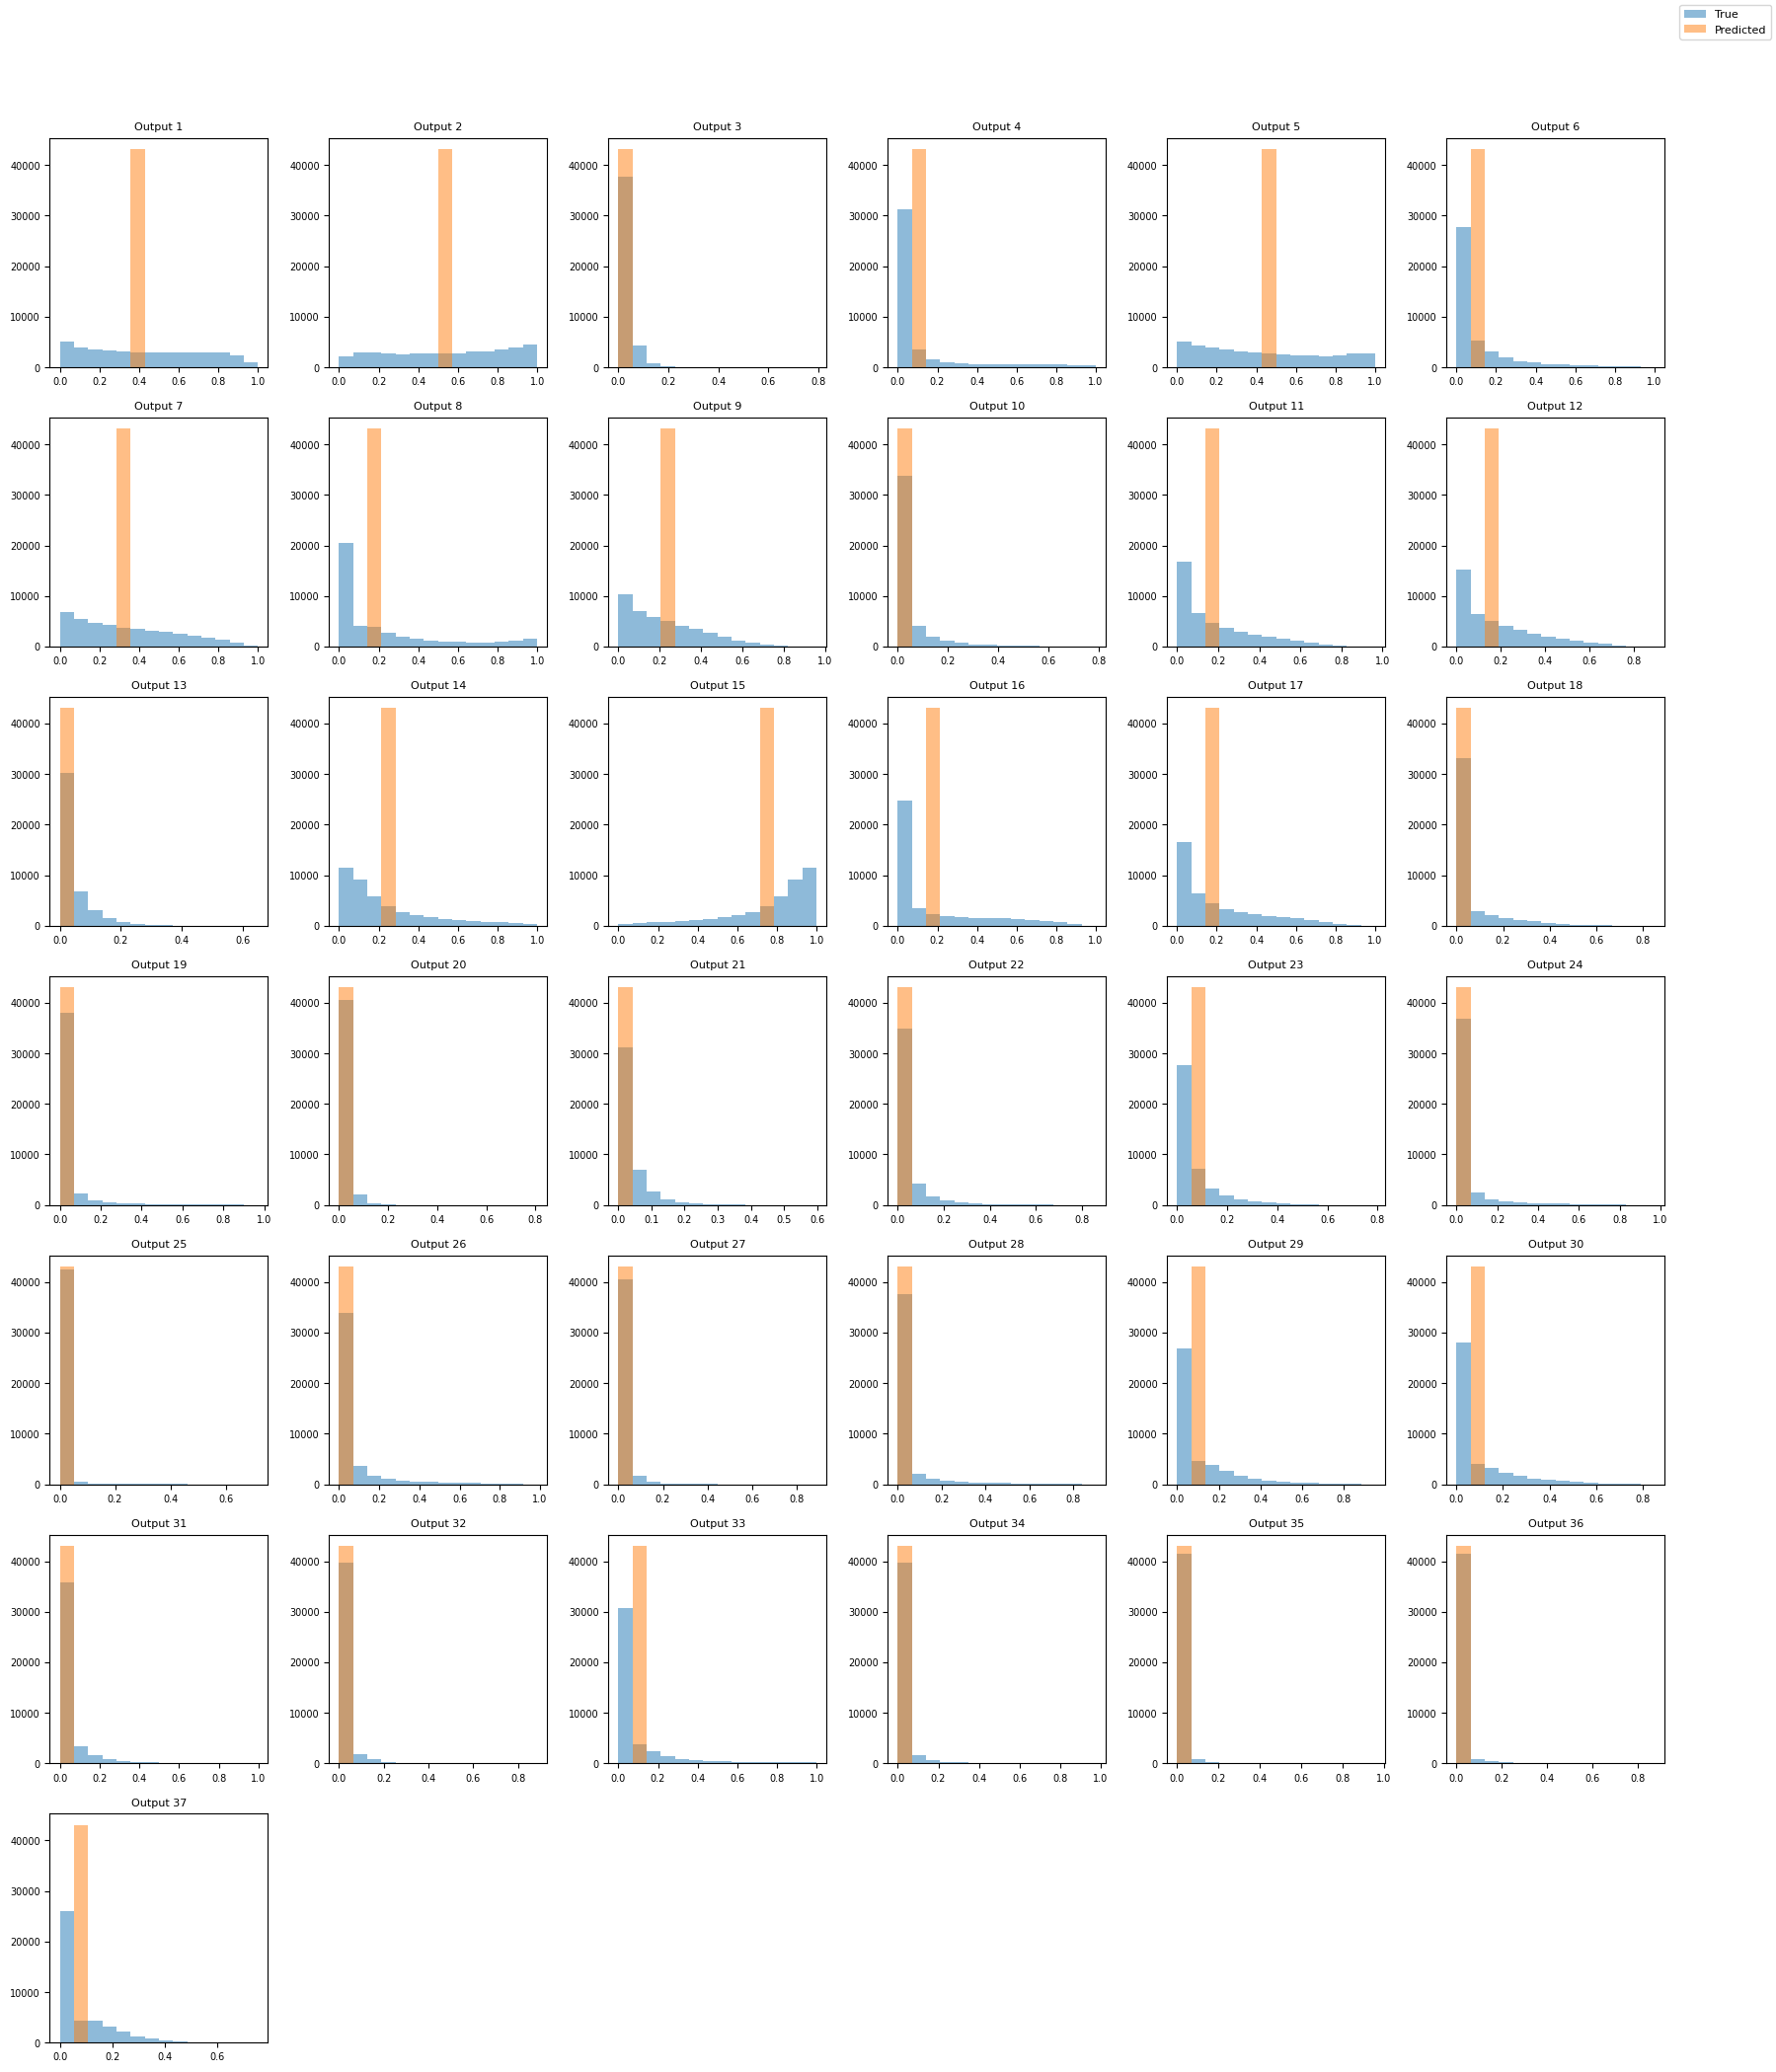

In [37]:
plot_model_outputs(y_test, preds)